# 00 — Descobrindo os dados com ADSS

Workshop SAB — AI-Scope / ADSS

Chamadas básicas para ver tabelas, colunas, imagens, alertas e uma pequena amostra de dados.


In [28]:
import adss

cl = adss.ADSSClient(base_url="https://ai-scope.cbpf.br/")


## Tabelas e colunas


In [30]:
metadata = cl.get_database_metadata()
print("Schemas:", metadata.schema_names())

Schemas: ['desi', 'lapa', 'public', 'splus_vacs', 'splus', 'arandu', 'lapa_mvp0']


In [32]:
for schema_name in ("public", "desi", "splus"):
    schema = metadata.get_schema(schema_name)
    if schema is not None:
        print(f"{schema_name}: {schema.table_names()[:20]}")

# Para imprimir todas as tabelas e colunas:
# cl.pretty_print_db_metadata(metadata)


public: ['gaia_spec_continuous_dr3', 'legacy_dr10_photoz', 'allwise', 'ztf_bts', 'delve_dr2_photoz', 'milliquas', 'ztf_dr22', 'gaia_dr3', 'apogee_synspec_dr17', 'geodist_gaia_dr3', 'photoz_lsdr10_mbpz', 'delve_dr2_cleaned']
desi: ['desi_specz_dr1', 'desi_dr1']
splus: ['splus_dr5', 'splus_dr4']


In [33]:
for schema_name, table_name in (
    ("public", "gaia_dr3"),
    ("desi", "desi_specz_dr1"),
    ("desi", "desi_dr1"),
    ("public", "ztf_dr22"),
):
    table = metadata.get_table(schema_name, table_name)
    if table is not None:
        print(f"{schema_name}.{table_name}: {len(table.columns)} colunas")
        print(table.column_names()[:30])


public.gaia_dr3: 152 colunas
['solution_id', 'designation', 'source_id', 'random_index', 'ref_epoch', 'ra', 'ra_error', 'dec', 'dec_error', 'parallax', 'parallax_error', 'parallax_over_error', 'pm', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ra_dec_corr', 'ra_parallax_corr', 'ra_pmra_corr', 'ra_pmdec_corr', 'dec_parallax_corr', 'dec_pmra_corr', 'dec_pmdec_corr', 'parallax_pmra_corr', 'parallax_pmdec_corr', 'pmra_pmdec_corr', 'astrometric_n_obs_al', 'astrometric_n_obs_ac', 'astrometric_n_good_obs_al']
desi.desi_specz_dr1: 148 colunas
['id', 'survey', 'program', 'firstnight', 'lastnight', 'spgrpval', 'z', 'zerr', 'zwarn', 'chi2', 'coeff', 'npixels', 'spectype', 'subtype', 'ncoeff', 'deltachi2', 'petal_loc', 'device_loc', 'location', 'fiber', 'coadd_fiberstatus', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'lambda_ref', 'fa_target', 'fa_type', 'objtype']
desi.desi_dr1: 39 colunas
['targetid', 'ra', 'dec', 'pmra', 'pmdec', 'ref_epoch', 'objtype', 'ebv', 'ls_flux_g', 'ls_flux_r', 'ls_flu

## Consulta Gaia perto de NGC 1365

Escreva uma consulta AstroQL a `public.gaia_dr3` para as fontes dentro de **0,1°** de RA **53,4017°**, Dec **−36,1402°**. Retorne `source_id`, `ra`, `dec` e as magnitudes médias `phot_g_mean_mag`, `phot_bp_mean_mag`, `phot_rp_mean_mag`. Use `cone(ra, dec, ra0, dec0, raio)` no `WHERE` e não limite as linhas: os mesmos resultados serão colocados sobre a imagem no final.

`query_and_wait` envia a consulta ao ADSS e aguarda a resposta; `.data` contém o `DataFrame`. A solução está em `outputs/respostas.txt` para conferência depois da tentativa.


In [ ]:
query = None  # Escreva a consulta AstroQL do enunciado.
if query is None:
    raise NotImplementedError("Complete query; veja outputs/respostas.txt após tentar.")

result = cl.query_and_wait(query_text=query, mode="astroql")
result.data


## Coleções e arquivos de imagem


In [23]:
collections = cl.get_collections()
[(item["id"], item["name"]) for item in collections]


[(4, 'splus dr1-dr4')]

In [24]:
if collections:
    files = cl.list_files(collection_id=collections[0]["id"], limit=5)
    for item in files:
        print(item.get("filename"), item.get("filter"),
              item.get("ra_center"), item.get("dec_center"))


MC0113_U_swpweight.fz U 4.736573730078494 -73.46159574983962
SPLUS-s17s23_U_swp.fz U 316.45153076969416 -21.580560694390957
SPLUS-s17s23_G_swp.fz G 316.45153076969416 -21.580560694390957
SPLUS-d232_U_swpweight.fz U 101.70394809751276 -29.463100277782356
fz_sorted_ima_swp.list None None None


## Categorias de alertas


In [25]:
cl.get_alert_categories()


[{'name': 'all',
  'description': 'All Roman Alerts',
  'created_at': '2026-03-30T13:28:09.407189'},
 {'name': 'rapid-high-confidence',
  'description': 'High-confidence transient candidates from RAPID',
  'created_at': '2026-09-15T19:40:06.525770'}]

## Imagens de NGC 1365

A galáxia espiral barrada [NGC 1365](https://chandra.harvard.edu/photo/2026/swift/) está coberta pela coleção S-PLUS DR1–DR4 nas bandas G, R e I. O exemplo usa suas coordenadas, mostra um stamp FITS em R e uma composição colorida I/R/G. Nada é salvo em disco.

`create_stamp_by_coordinates` retorna bytes FITS para um filtro; `fits.open(BytesIO(...))` lê os pixels sem salvar arquivo. O cabeçalho FITS contém o WCS, que relaciona posições no céu e pixels. `create_rgb_image_by_coordinates` combina I/R/G em uma imagem de exibição; seus canais não são medidas fotométricas calibradas.


In [15]:
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from PIL import Image

RA, DEC = 53.4017, -36.1402  # NGC 1365, graus (J2000)
SIZE_ARCMIN = 8

splus_collection = next(
    (item for item in collections
     if "splus" in item["name"].lower() and "dr4" in item["name"].lower()),
    None,
)
if splus_collection is None:
    raise RuntimeError("Coleção S-PLUS DR4 não encontrada.")
collection_id = splus_collection["id"]

for band in ("G", "R", "I"):
    files = cl.cone_search_images(collection_id, RA, DEC, radius=0.01,
                                  filter_name=band, limit=20)
    science = [item for item in files
               if str(item.get("filter", "")).upper() == band
               and "swpweight" not in str(item.get("filename", "")).lower()]
    if not science:
        raise RuntimeError(f"Sem imagem científica {band} em NGC 1365.")
    print(band, science[0]["filename"])


G SPLUS-s28s33_G_swp.fz
R SPLUS-s28s33_R_swp.fz
I SPLUS-s28s33_I_swp.fz


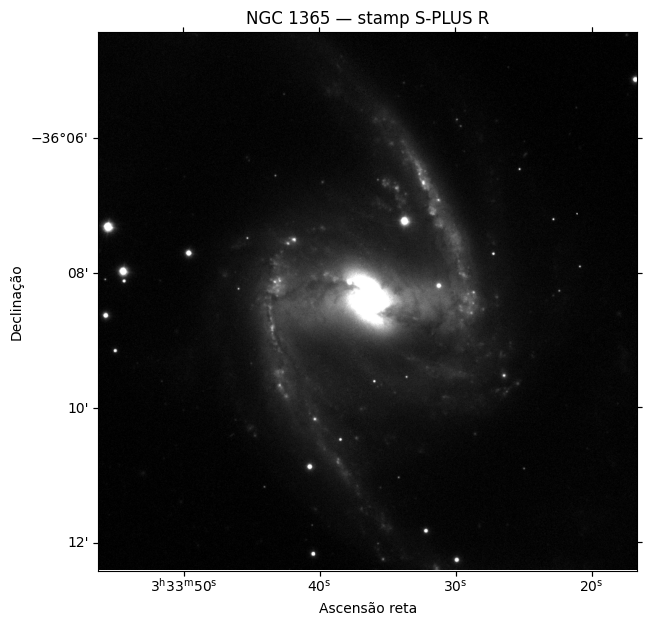

In [16]:
stamp_bytes = cl.create_stamp_by_coordinates(
    collection_id=collection_id, ra=RA, dec=DEC, size=SIZE_ARCMIN,
    filter="R", size_unit="arcmin", format="fits", pattern="swp.",
)
with fits.open(BytesIO(stamp_bytes)) as hdul:
    hdu = next(h for h in hdul if h.data is not None)
    stamp = hdu.data.copy()
    stamp_wcs = WCS(hdu.header).celestial

lo, hi = np.nanpercentile(stamp, [5, 99.5])
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": stamp_wcs})
ax.imshow(stamp, origin="lower", cmap="gray", vmin=lo, vmax=hi)
ax.set(title="NGC 1365 — stamp S-PLUS R", xlabel="Ascensão reta", ylabel="Declinação")
plt.show()


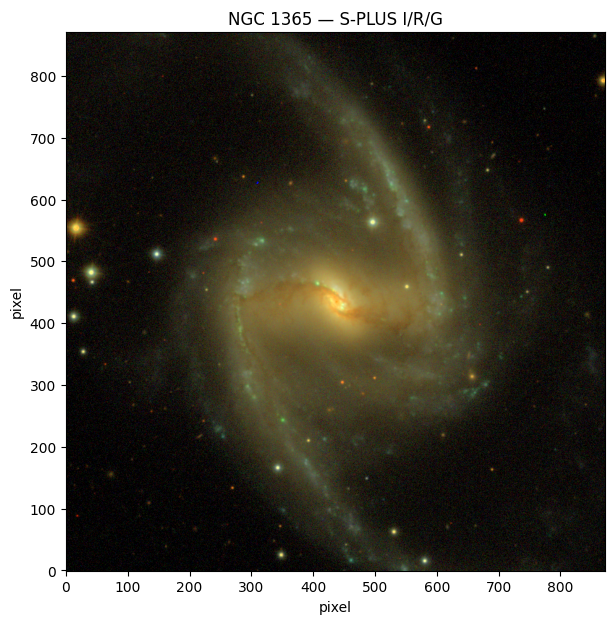

In [17]:
rgb_bytes = cl.create_rgb_image_by_coordinates(
    collection_id=collection_id, ra=RA, dec=DEC, size=SIZE_ARCMIN,
    r_filter="I", g_filter="R", b_filter="G", size_unit="arcmin",
    pattern="swp.",
)
rgb = Image.open(BytesIO(rgb_bytes))
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(rgb, origin="lower")
ax.set(title="NGC 1365 — S-PLUS I/R/G", xlabel="pixel", ylabel="pixel")
plt.show()


## Fontes Gaia DR3 sobre a imagem

Use o `result.data` da consulta Gaia feita acima. O WCS do stamp transforma as coordenadas `ra` e `dec` em pixels; filtre os pontos que caem dentro da imagem. A cor de cada marcador representa a magnitude G do Gaia. Não é preciso consultar o catálogo S-PLUS novamente.


In [ ]:
gaia_sources = result.data
if gaia_sources.empty:
    raise RuntimeError("A consulta Gaia não retornou fontes nesta região.")
if rgb.size != stamp.shape[::-1]:
    raise ValueError("RGB e stamp R têm dimensões diferentes; confira a cobertura.")

ra = gaia_sources["ra"].to_numpy(dtype=float)
dec = gaia_sources["dec"].to_numpy(dtype=float)
g_mag = gaia_sources["phot_g_mean_mag"].to_numpy(dtype=float)
x, y = stamp_wcs.world_to_pixel_values(ra, dec)
inside = (np.isfinite(x) & np.isfinite(y) & np.isfinite(g_mag)
          & (x >= 0) & (x < stamp.shape[1])
          & (y >= 0) & (y < stamp.shape[0]))
print(f"Fontes Gaia com G válida dentro do stamp: {inside.sum()}")

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": stamp_wcs})
ax.imshow(rgb, origin="lower")
markers = ax.scatter(x[inside], y[inside], c=g_mag[inside], s=18,
                     cmap="viridis_r", edgecolors="black", linewidths=0.25)
fig.colorbar(markers, ax=ax, label="Gaia G [mag]")
ax.set(title=f"NGC 1365 — {inside.sum()} fontes Gaia DR3",
       xlabel="Ascensão reta", ylabel="Declinação")
plt.show()
